In [1]:
#LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#READ_CSV

df = pd.read_csv('diabetes.csv')

In [3]:
#COUNTS OF INDIVIDUALS WITH SAME CHARACTERISTICS + DIABETES CONDITION

counts_bp = df.groupby(['Diabetes_012', 'HighBP']).size().reset_index(name="count")
counts_chol = df.groupby(['Diabetes_012', 'HighChol']).size().reset_index(name="count")
counts_check = df.groupby(['Diabetes_012', 'CholCheck']).size().reset_index(name="count")
counts_smoker = df.groupby(['Diabetes_012', 'Smoker']).size().reset_index(name="count")
counts_stroke = df.groupby(['Diabetes_012', 'Stroke']).size().reset_index(name="count")
counts_heart = df.groupby(['Diabetes_012', 'HeartDiseaseorAttack']).size().reset_index(name="count")
counts_phys = df.groupby(['Diabetes_012', 'PhysActivity']).size().reset_index(name="count")
counts_fruit = df.groupby(['Diabetes_012', 'Fruits']).size().reset_index(name="count")
counts_veggies = df.groupby(['Diabetes_012', 'Veggies']).size().reset_index(name="count")
counts_alco = df.groupby(['Diabetes_012', 'HvyAlcoholConsump']).size().reset_index(name="count")
counts_hcare = df.groupby(['Diabetes_012', 'AnyHealthcare']).size().reset_index(name="count")
counts_doc = df.groupby(['Diabetes_012', 'NoDocbcCost']).size().reset_index(name="count")
counts_walk = df.groupby(['Diabetes_012', 'DiffWalk']).size().reset_index(name="count")
counts_sex = df.groupby(['Diabetes_012', 'Sex']).size().reset_index(name="count")
counts_age = df.groupby(['Diabetes_012', 'Age']).size().reset_index(name="count")

In [4]:
#PROPORTIONS OF INDIVIDUALS WITH SAME CHARACTERISTICS + DIABETES CONDITION

proportions_bp = counts_bp.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_bp, on = 'Diabetes_012')
proportions_bp['proportion'] = proportions_bp['count'] / proportions_bp['total']

proportions_chol = counts_chol.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_chol, on = 'Diabetes_012')
proportions_chol['proportion'] = proportions_chol['count'] / proportions_chol['total']

proportions_check = counts_bp.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_check, on = 'Diabetes_012')
proportions_check['proportion'] = proportions_check['count'] / proportions_check['total']

proportions_smoker = counts_smoker.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_smoker, on = 'Diabetes_012')
proportions_smoker['proportion'] = proportions_smoker['count'] / proportions_smoker['total']

proportions_stroke = counts_stroke.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_stroke, on = 'Diabetes_012')
proportions_stroke['proportion'] = proportions_stroke['count'] / proportions_stroke['total']

proportions_heart = counts_heart.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_heart, on = 'Diabetes_012')
proportions_heart['proportion'] = proportions_heart['count'] / proportions_heart['total']

proportions_phys = counts_phys.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_phys, on = 'Diabetes_012')
proportions_phys['proportion'] = proportions_phys['count'] / proportions_phys['total']

proportions_fruit = counts_fruit.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_fruit, on = 'Diabetes_012')
proportions_fruit['proportion'] = proportions_fruit['count'] / proportions_fruit['total']

proportions_veggies = counts_veggies.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_veggies, on = 'Diabetes_012')
proportions_veggies['proportion'] = proportions_veggies['count'] / proportions_veggies['total']

proportions_alco = counts_alco.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_alco, on = 'Diabetes_012')
proportions_alco['proportion'] = proportions_alco['count'] / proportions_alco['total']

proportions_hcare = counts_hcare.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_hcare, on = 'Diabetes_012')
proportions_hcare['proportion'] = proportions_hcare['count'] / proportions_hcare['total']

proportions_doc = counts_doc.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_doc, on = 'Diabetes_012')
proportions_doc['proportion'] = proportions_doc['count'] / proportions_doc['total']

proportions_walk = counts_walk.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_walk, on = 'Diabetes_012')
proportions_walk['proportion'] = proportions_walk['count'] / proportions_walk['total']

proportions_sex = counts_sex.groupby('Diabetes_012').agg(total = ('count', 'sum')).merge(counts_sex, on = 'Diabetes_012')
proportions_sex['proportion'] = proportions_sex['count'] / proportions_sex['total']

proportions_age = counts_age.groupby(['Diabetes_012']).agg(total = ('count', 'sum')).merge(counts_age, on = 'Diabetes_012')
proportions_age['proportion'] = proportions_age['count'] / proportions_age['total']

Text(0.5, 1.0, 'Correlation Heatmap')

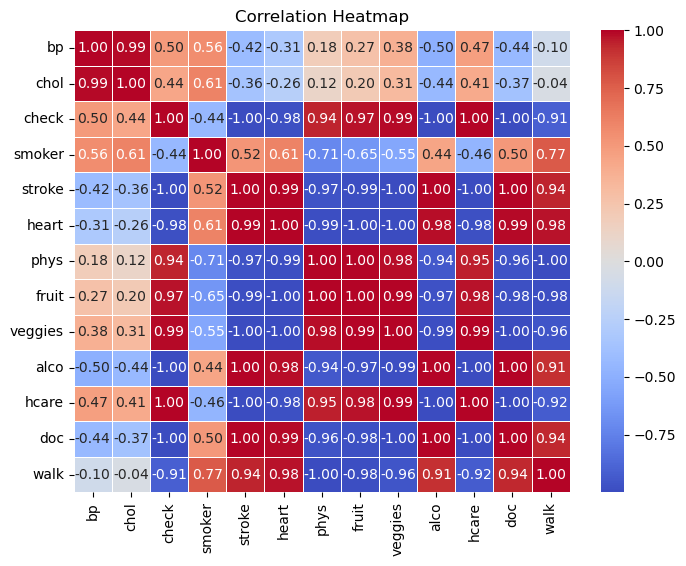

In [5]:
#HEAT MAP CONSTRUCTION

data_proportions = {
    'bp': proportions_bp['proportion'],
    'chol':proportions_chol['proportion'],
    'check':proportions_check['proportion'],
    'smoker':proportions_smoker['proportion'],
    'stroke':proportions_stroke['proportion'],
    'heart':proportions_heart['proportion'],
    'phys':proportions_phys['proportion'],
    'fruit':proportions_fruit['proportion'],
    'veggies':proportions_veggies['proportion'],
    'alco':proportions_alco['proportion'],
    'hcare':proportions_hcare['proportion'],
    'doc':proportions_doc['proportion'],
    'walk':proportions_walk['proportion'],
}
dataframe = pd.DataFrame(data_proportions, 
                         columns=['bp', 'chol', 'check', 'smoker', 'stroke', 
                                  'heart', 'phys', 'fruit', 'veggies', 'alco', 'hcare',
                                 'doc', 'walk'])

matrix = dataframe.corr()
plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")

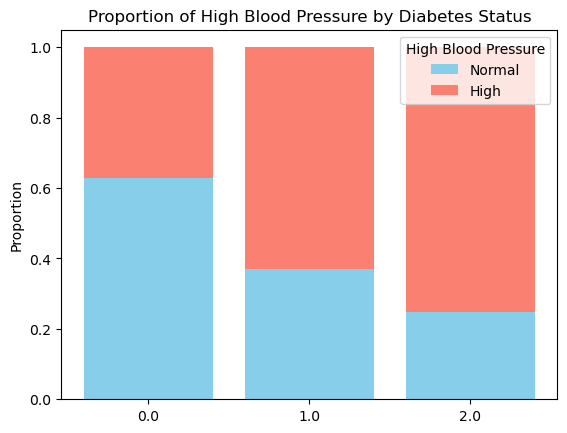

In [6]:
#Stacked bar plot High BP

x = proportions_bp['Diabetes_012'].astype('string').unique()
y_low = proportions_bp[proportions_bp['HighBP'] == 0]
y_high = proportions_bp[proportions_bp['HighBP'] == 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of High Blood Pressure by Diabetes Status')
plt.legend(title='High Blood Pressure', labels=['Normal', 'High'])

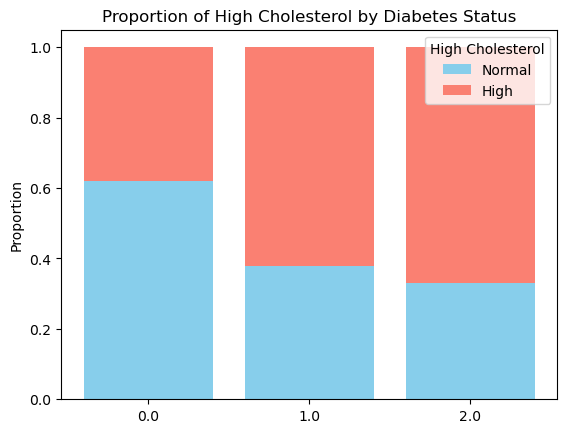

In [7]:
#Stacked bar plot High Chol

x = proportions_chol['Diabetes_012'].astype('string').unique()
y_low = proportions_chol[proportions_chol['HighChol']== 0]
y_high = proportions_chol[proportions_chol['HighChol']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of High Cholesterol by Diabetes Status')
plt.legend(title='High Cholesterol', labels=['Normal', 'High'])

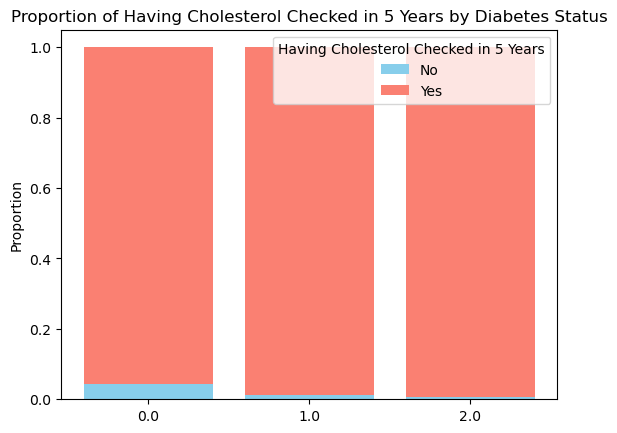

In [8]:
#Stacked bar plot Chol Check

x = proportions_check['Diabetes_012'].astype('string').unique()
y_low = proportions_check[proportions_check['CholCheck']== 0]
y_high = proportions_check[proportions_check['CholCheck']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Having Cholesterol Checked in 5 Years by Diabetes Status')
plt.legend(title='Having Cholesterol Checked in 5 Years', labels=['No', 'Yes'])

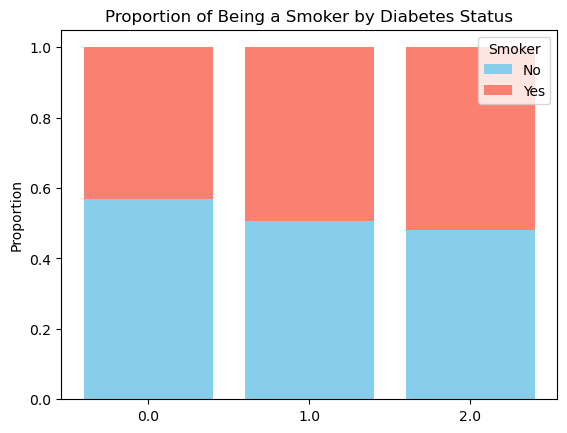

In [9]:
#Stacked bar plot Smoker

x = proportions_smoker['Diabetes_012'].astype('string').unique()
y_low = proportions_smoker[proportions_smoker['Smoker']== 0]
y_high = proportions_smoker[proportions_smoker['Smoker']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Being a Smoker by Diabetes Status')
plt.legend(title='Smoker', labels=['No', 'Yes'])

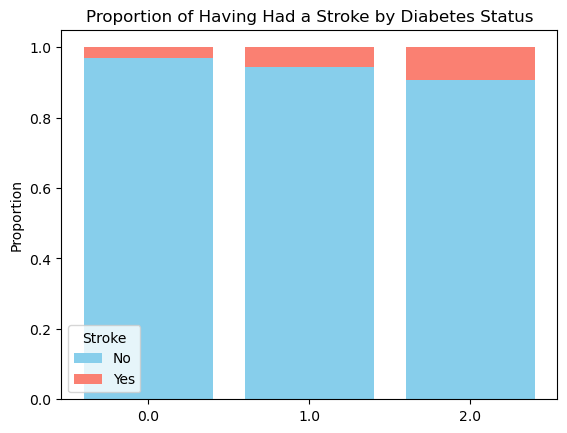

In [10]:
#Stacked bar plot Stroke

x = proportions_stroke['Diabetes_012'].astype('string').unique()
y_low = proportions_stroke[proportions_stroke['Stroke']== 0]
y_high = proportions_stroke[proportions_stroke['Stroke']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Having Had a Stroke by Diabetes Status')
plt.legend(title='Stroke', labels=['No', 'Yes'])

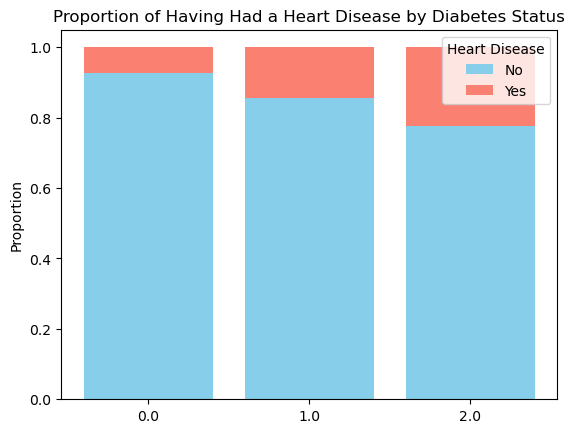

In [11]:
#Stacked bar plot Heart Disease

x = proportions_heart['Diabetes_012'].astype('string').unique()
y_low = proportions_heart[proportions_heart['HeartDiseaseorAttack']== 0]
y_high = proportions_heart[proportions_heart['HeartDiseaseorAttack']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Having Had a Heart Disease by Diabetes Status')
plt.legend(title='Heart Disease', labels=['No', 'Yes'])

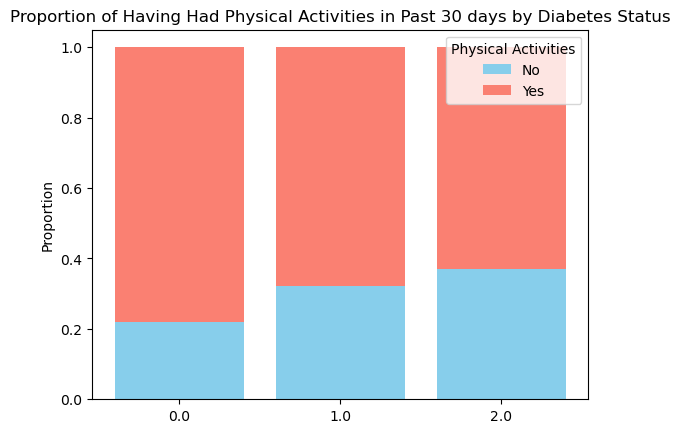

In [12]:
#Stacked bar plot Phys Activities

x = proportions_phys['Diabetes_012'].astype('string').unique()
y_low = proportions_phys[proportions_phys['PhysActivity']== 0]
y_high = proportions_phys[proportions_phys['PhysActivity']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Having Had Physical Activities in Past 30 days by Diabetes Status')
plt.legend(title='Physical Activities', labels=['No', 'Yes'])

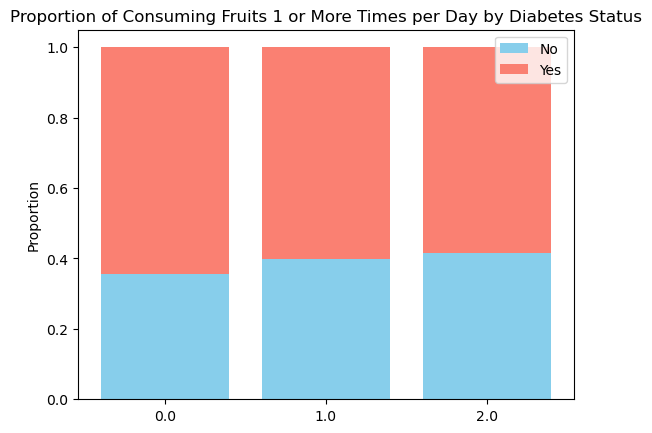

In [13]:
#Stacked bar plot Fruits

x = proportions_fruit['Diabetes_012'].astype('string').unique()
y_low = proportions_fruit[proportions_fruit['Fruits']== 0]
y_high = proportions_fruit[proportions_fruit['Fruits']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Consuming Fruits 1 or More Times per Day by Diabetes Status')
plt.legend(labels=['No', 'Yes'])

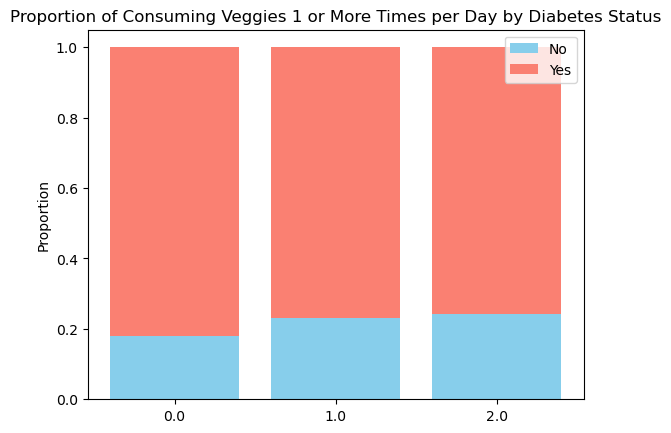

In [14]:
#Stacked bar plot Veggies

x = proportions_veggies['Diabetes_012'].astype('string').unique()
y_low = proportions_veggies[proportions_veggies['Veggies']== 0]
y_high = proportions_veggies[proportions_veggies['Veggies']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Consuming Veggies 1 or More Times per Day by Diabetes Status')
plt.legend(labels=['No', 'Yes'])

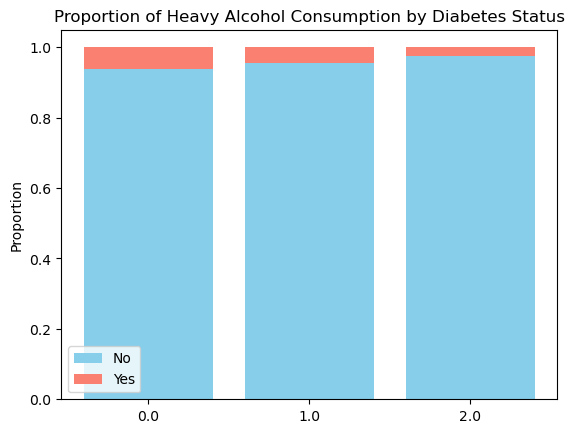

In [15]:
#Stacked bar plot Alcohol

x = proportions_alco['Diabetes_012'].astype('string').unique()
y_low = proportions_alco[proportions_alco['HvyAlcoholConsump']== 0]
y_high = proportions_alco[proportions_alco['HvyAlcoholConsump']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Heavy Alcohol Consumption by Diabetes Status')
plt.legend(labels=['No', 'Yes'])

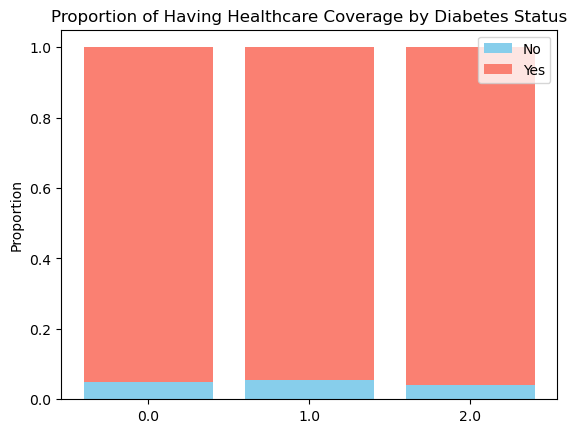

In [16]:
#Stacked bar plot HealthCare

x = proportions_hcare['Diabetes_012'].astype('string').unique()
y_low = proportions_hcare[proportions_hcare['AnyHealthcare']== 0]
y_high = proportions_hcare[proportions_hcare['AnyHealthcare']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Having Healthcare Coverage by Diabetes Status')
plt.legend(labels=['No', 'Yes'])

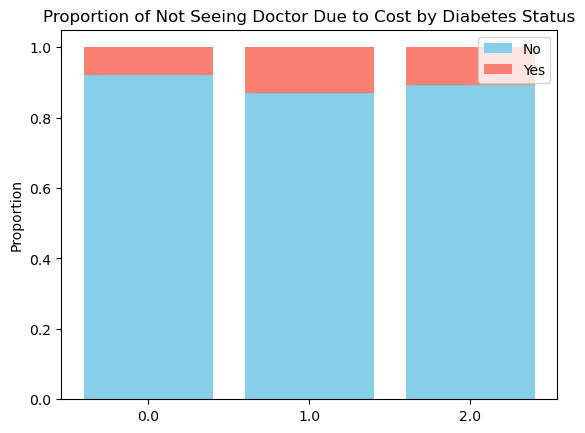

In [17]:
#Stacked bar plot Doc

x = proportions_doc['Diabetes_012'].astype('string').unique()
y_low = proportions_doc[proportions_doc['NoDocbcCost']== 0]
y_high = proportions_doc[proportions_doc['NoDocbcCost']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Not Seeing Doctor Due to Cost by Diabetes Status')
plt.legend(labels=['No', 'Yes'])

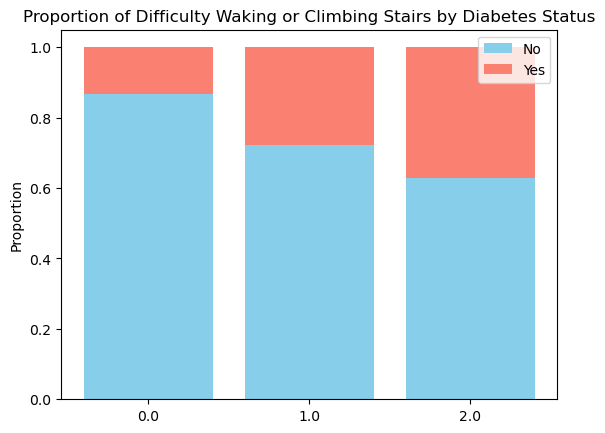

In [18]:
#Stacked bar plot Walk

x = proportions_walk['Diabetes_012'].astype('string').unique()
y_low = proportions_walk[proportions_walk['DiffWalk']== 0]
y_high = proportions_walk[proportions_walk['DiffWalk']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Difficulty Waking or Climbing Stairs by Diabetes Status')
plt.legend(labels=['No', 'Yes'])

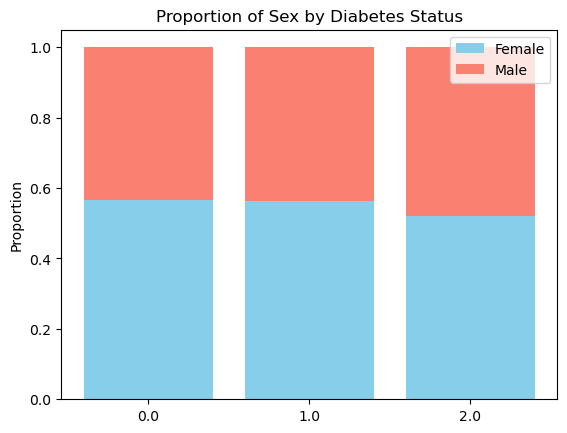

In [19]:
#Stacked bar plot Sex

x = proportions_sex['Diabetes_012'].astype('string').unique()
y_low = proportions_sex[proportions_sex['Sex']== 0]
y_high = proportions_sex[proportions_sex['Sex']== 1]
plt.bar(x, y_low['proportion'], color = 'skyblue')
plt.bar(x, y_high['proportion'], bottom = y_low['proportion'], color = 'salmon')

plt.ylabel('Proportion')
plt.title('Proportion of Sex by Diabetes Status')
plt.legend(labels=['Female', 'Male'])

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [Text(0, 0, '18-24'),
  Text(1, 0, '25-29'),
  Text(2, 0, '30-34'),
  Text(3, 0, '35-39'),
  Text(4, 0, '40-44'),
  Text(5, 0, '45-49'),
  Text(6, 0, '50-54'),
  Text(7, 0, '55-59'),
  Text(8, 0, '60-64'),
  Text(9, 0, '65-69'),
  Text(10, 0, '70-74'),
  Text(11, 0, '75-79'),
  Text(12, 0, '80+')])

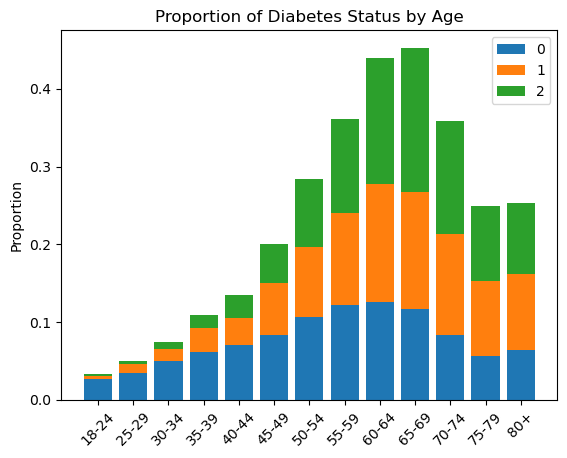

In [20]:
#Stacked bar plot Age

x = ['18-24','25-29','30-34','35-39','40-44','45-49','50-54',
              '55-59','60-64','65-69','70-74','75-79','80+']
y0 = proportions_age[proportions_age['Diabetes_012']== 0]['proportion'].to_numpy()
y1 = proportions_age[proportions_age['Diabetes_012']== 1]['proportion'].to_numpy()
y2 = proportions_age[proportions_age['Diabetes_012']== 2]['proportion'].to_numpy()

plt.bar(x, y0)
plt.bar(x, y1, bottom = y0)
plt.bar(x, y2, bottom = y0 + y1)

plt.ylabel('Proportion')
plt.title('Proportion of Diabetes Status by Age')
plt.legend(labels=['0', '1', '2'])
plt.xticks(rotation=45)

Text(0.5, 1.0, 'BMI distribution by Diabetes status (no outlier shown)')

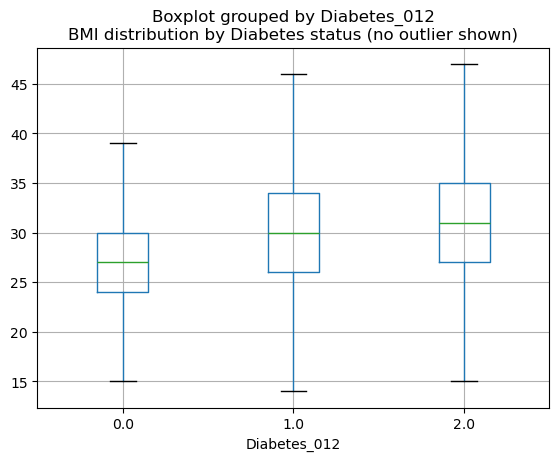

In [22]:
df.boxplot(column="BMI", by="Diabetes_012", showfliers=False)
plt.title("BMI distribution by Diabetes status (no outlier shown)")